# Klasifikasi Citra Sepatu (Rapi vs. Berantakan)
### Pemodelan dan Evaluasi Model Klasifikasi Berbasis 14 Fitur Statistik Orde Pertama dan Orde Kedua

## TAHAP 4: MODELING (Pemodelan)

### 4.1 Memuat Dataset Fitur
Tabel fitur hasil `main.ipynb` dibaca kembali dari CSV, sehingga ekstraksi fitur tidak perlu diulang.
- **Fitur masukan ($X$)**: 14 kolom fitur numerik.
- **Target ($y$)**: kolom `label` (`rapi` / `berantakan`).
- Kolom `id` dan `nama_file` hanya identitas dan tidak dipakai sebagai masukan model.

In [12]:
import os
import pandas as pd

FOLDER_HASIL = "hasil"
KELAS = ["rapi", "berantakan"]

dataset = pd.read_csv(os.path.join(FOLDER_HASIL, "fitur_lengkap.csv"))
FITUR = [c for c in dataset.columns if c not in ("id", "nama_file", "label")]

X = dataset[FITUR]
y = dataset["label"]

print("=== DATASET FITUR ===")
print("Ukuran tabel :", dataset.shape)
print("Jumlah fitur :", len(FITUR))
print("Fitur        :", FITUR)
print("Distribusi kelas:")
print(y.value_counts().to_string())
dataset.head()

=== DATASET FITUR ===
Ukuran tabel : (194, 17)
Jumlah fitur : 14
Fitur        : ['mean_r', 'mean_g', 'mean_b', 'std_r', 'std_g', 'std_b', 'skew_r', 'skew_g', 'skew_b', 'energi', 'entropi', 'kontras', 'korelasi', 'homogenitas']
Distribusi kelas:
label
rapi          97
berantakan    97


,id,nama_file,mean_r,mean_g,mean_b,std_r,std_g,std_b,skew_r,skew_g,skew_b,energi,entropi,kontras,korelasi,homogenitas,label
0,1,24-003 Rapi 2.jpg,167.5277,145.6219,129.1982,58.7598,58.7238,59.4027,-0.7423,-0.3384,-0.1417,0.000696,12.092472,300.062408,0.954200,0.370522,rapi
1,2,24-003 Rapi 3.jpg,151.7979,144.1809,136.9614,54.8708,62.4687,69.7364,-0.6127,-0.2997,-0.2497,0.000607,12.105675,340.629779,0.951172,0.387804,rapi
2,3,24-003 Rapi.jpeg,112.6111,105.5900,102.3779,50.9505,56.4039,62.8547,0.0469,0.1900,0.2648,0.000420,12.436947,258.886167,0.956552,0.339651,rapi
3,4,24-006 Rapi 1.jpg,99.6618,84.9688,82.1308,61.3118,59.8151,61.1633,0.3082,0.8236,0.8788,0.000392,12.590984,424.356556,0.939107,0.312549,rapi
4,5,24-006 Rapi 2.jpg,111.9111,102.2413,99.2738,63.3843,66.3158,67.5407,-0.0223,0.2308,0.2786,0.000749,12.022263,382.180239,0.954788,0.404929,rapi


### 4.2 Pembagian Data Latih (80%) dan Data Uji (20%)
Pemisahan data dilakukan secara **Stratified Sampling** dengan `train_test_split`:
- **Total dataset**: 194 citra
- **Data latih (80%)**: 155 citra (78 rapi, 77 berantakan)
- **Data uji (20%)**: 39 citra (19 rapi, 20 berantakan)
- Parameter `stratify=y` menjaga proporsi kelas (50:50) sama di data latih dan data uji.
- Parameter `random_state=42` membuat pembagian selalu sama setiap notebook dijalankan, sehingga hasil dapat diulang.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("=== PARTISI DATASET ===")
print(f"Total dataset : {len(X)} citra")
print(f"Data latih    : {len(X_train)} citra ({len(X_train) / len(X):.0%}) -> rapi={sum(y_train == 'rapi')}, berantakan={sum(y_train == 'berantakan')}")
print(f"Data uji      : {len(X_test)} citra ({len(X_test) / len(X):.0%}) -> rapi={sum(y_test == 'rapi')}, berantakan={sum(y_test == 'berantakan')}")
pd.DataFrame({"latih": y_train.value_counts(), "uji": y_test.value_counts()})

=== PARTISI DATASET ===
Total dataset : 194 citra
Data latih    : 155 citra (80%) -> rapi=78, berantakan=77
Data uji      : 39 citra (20%) -> rapi=19, berantakan=20


,latih,uji
label,,
berantakan,77,20
rapi,78,19


### 4.3 Standardisasi Fitur (*Z-Score*)
- **Pengertian**: Mengubah setiap fitur agar memiliki rata-rata 0 dan standar deviasi 1:
$$z = \frac{x - \mu}{\sigma}$$
- **Alasan**: Skala fitur sangat berbeda. *Mean* RGB bernilai 0–255, kontras bisa ratusan, sedangkan energi dan korelasi bernilai 0–1. Model berbasis jarak (KNN, SVM) dan bobot (Logistic Regression) akan didominasi fitur berskala besar jika tidak distandardisasi.
- **Penerapan**: `StandardScaler` dipasang di dalam `Pipeline`, sehingga $\mu$ dan $\sigma$ hanya dihitung dari data latih pada setiap *fold*. Model berbasis pohon (Decision Tree, Random Forest, boosting) tidak memerlukan standardisasi karena keputusannya berupa ambang batas pada satu fitur.

### 4.4 Definisi Model

#### A. Model Standar (*Single Models*)
| Model | Cara Kerja | Standardisasi | Parameter yang di-*tuning* |
| :--- | :--- | :---: | :--- |
| **K-Nearest Neighbors (KNN)** | Mencari $k$ citra latih terdekat (jarak Euclidean) lalu mengambil kelas mayoritas | Ya | `n_neighbors`, `weights` |
| **Support Vector Machine (SVM RBF)** | Mencari bidang pemisah dengan margin terlebar; kernel RBF $K(x, x') = \exp(-\gamma\lVert x - x'\rVert^2)$ memungkinkan batas melengkung | Ya | `C`, `gamma` |
| **Decision Tree** | Membagi data berulang dengan aturan "fitur ≤ ambang" hingga membentuk pohon keputusan | Tidak | `max_depth`, `min_samples_leaf` |
| **Logistic Regression** | Model linear yang mengubah skor berbobot menjadi peluang dengan fungsi sigmoid $P = \frac{1}{1 + e^{-(w_0 + w \cdot x)}}$ | Ya | `C` |
| **Gaussian Naive Bayes** | Teorema Bayes dengan asumsi tiap fitur saling bebas dan berdistribusi normal di setiap kelas | Ya | `var_smoothing` |

#### B. Model Ensemble Learning
| Model | Cara Kerja | Parameter yang di-*tuning* |
| :--- | :--- | :--- |
| **Random Forest** (*bagging*) | Banyak pohon dilatih pada sampel acak; prediksi akhir hasil *voting* | `max_depth`, `min_samples_leaf` |
| **AdaBoost** (*boosting*) | Pohon kecil dibangun berurutan; data yang salah diprediksi diberi bobot lebih besar pada pohon berikutnya | `n_estimators`, `learning_rate` |
| **Gradient Boosting** (*boosting*) | Pohon kecil dibangun berurutan; setiap pohon memperbaiki sisa kesalahan (*residual*) pohon sebelumnya | `n_estimators`, `learning_rate`, `max_depth` |
| **Voting Classifier** (*soft voting*) | Rata-rata peluang dari SVM, Random Forest, dan Gradient Boosting | bobot tiap model |

In [14]:
from itertools import product
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, VotingClassifier)

# Setiap entri: (kategori, model, grid parameter untuk GridSearchCV)
daftar_model = {
    "KNN": ("Model Standar",
            make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15],
             "kneighborsclassifier__weights": ["uniform", "distance"]}),
    "SVM (RBF)": ("Model Standar",
                  make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42)),
                  {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1]}),
    "Decision Tree": ("Model Standar",
                      DecisionTreeClassifier(random_state=42),
                      {"max_depth": [2, 3, 5, 8, None], "min_samples_leaf": [1, 3, 5, 10]}),
    "Logistic Regression": ("Model Standar",
                            make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                            {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "Naive Bayes": ("Model Standar",
                    make_pipeline(StandardScaler(), GaussianNB()),
                    {"gaussiannb__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}),
    "Random Forest": ("Ensemble Learning",
                      RandomForestClassifier(n_estimators=300, random_state=42),
                      {"max_depth": [None, 5, 10], "min_samples_leaf": [1, 3, 5]}),
    "AdaBoost": ("Ensemble Learning",
                 AdaBoostClassifier(random_state=42),
                 {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1, 0.5, 1.0]}),
    "Gradient Boosting": ("Ensemble Learning",
                          GradientBoostingClassifier(random_state=42),
                          {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]}),
    "Voting Classifier": ("Ensemble Learning",
                          VotingClassifier(
                              estimators=[("svm", make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=42))),
                                          ("rf", RandomForestClassifier(n_estimators=300, random_state=42)),
                                          ("gb", GradientBoostingClassifier(random_state=42))],
                              voting="soft"),
                          {"weights": [[1, 1, 1], [2, 1, 1], [1, 2, 1], [1, 1, 2]]}),
}

print("Model yang diuji:")
for nama, (kategori, _, grid) in daftar_model.items():
    print(f"  {kategori:17} | {nama:19} | {len(list(product(*grid.values())))} kombinasi parameter")

Model yang diuji:
  Model Standar     | KNN                 | 12 kombinasi parameter
  Model Standar     | SVM (RBF)           | 12 kombinasi parameter
  Model Standar     | Decision Tree       | 20 kombinasi parameter
  Model Standar     | Logistic Regression | 5 kombinasi parameter
  Model Standar     | Naive Bayes         | 5 kombinasi parameter
  Ensemble Learning | Random Forest       | 9 kombinasi parameter
  Ensemble Learning | AdaBoost            | 12 kombinasi parameter
  Ensemble Learning | Gradient Boosting   | 12 kombinasi parameter
  Ensemble Learning | Voting Classifier   | 4 kombinasi parameter


### 4.5 Pelatihan dan *Tuning Hyperparameter*
Setiap model dilatih dengan prosedur yang sama agar perbandingannya adil:
1. **`GridSearchCV`** mencoba semua kombinasi parameter pada **data latih saja**, memakai 5-fold *Stratified K-Fold*.
2. Kombinasi dengan **rata-rata F1 makro** tertinggi dipilih, lalu model dilatih ulang pada seluruh data latih.
3. Model terbaik diuji pada **data uji** yang belum pernah dilihat.

| Kolom Hasil | Arti |
| :--- | :--- |
| `acc_train` | akurasi pada data latih |
| `f1_cv` | rata-rata F1 makro 5-fold pada data latih (kestabilan model) |
| `acc_test`, `f1_test` | akurasi dan F1 makro pada data uji (kemampuan generalisasi) |

In [15]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_terlatih, hasil = {}, []
for nama, (kategori, model, grid) in daftar_model.items():
    gs = GridSearchCV(model, grid, cv=cv, scoring="f1_macro")
    gs.fit(X_train, y_train)
    model_terlatih[nama] = gs.best_estimator_

    pred_train = gs.predict(X_train)
    pred_test = gs.predict(X_test)
    hasil.append({
        "kategori": kategori, "model": nama,
        "acc_train": accuracy_score(y_train, pred_train),
        "f1_cv": gs.best_score_,
        "acc_test": accuracy_score(y_test, pred_test),
        "precision": precision_score(y_test, pred_test, average="macro", zero_division=0),
        "recall": recall_score(y_test, pred_test, average="macro", zero_division=0),
        "f1_test": f1_score(y_test, pred_test, average="macro", zero_division=0),
        "parameter": {k.split("__")[-1]: v for k, v in gs.best_params_.items()},
    })
    print(f"{nama:19} selesai | parameter terbaik: {hasil[-1]['parameter']}")

df_hasil = pd.DataFrame(hasil)

KNN                 selesai | parameter terbaik: {'n_neighbors': 11, 'weights': 'distance'}
SVM (RBF)           selesai | parameter terbaik: {'C': 10, 'gamma': 0.1}
Decision Tree       selesai | parameter terbaik: {'max_depth': 5, 'min_samples_leaf': 1}
Logistic Regression selesai | parameter terbaik: {'C': 10}
Naive Bayes         selesai | parameter terbaik: {'var_smoothing': 1e-09}
Random Forest       selesai | parameter terbaik: {'max_depth': None, 'min_samples_leaf': 1}
AdaBoost            selesai | parameter terbaik: {'learning_rate': 0.5, 'n_estimators': 200}
Gradient Boosting   selesai | parameter terbaik: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Voting Classifier   selesai | parameter terbaik: {'weights': [2, 1, 1]}


---

## TAHAP 5: EVALUATION (Evaluasi)

### 5.1 Performa pada Data Uji
Model diurutkan berdasarkan F1 makro pada data uji. Tabel juga disimpan ke `hasil/perbandingan_model.csv`.

In [16]:
import os

perbandingan = (df_hasil.drop(columns="parameter")
                .sort_values(["f1_test", "f1_cv"], ascending=False)
                .reset_index(drop=True).round(4))
perbandingan.to_csv(os.path.join(FOLDER_HASIL, "perbandingan_model.csv"), index=False)
perbandingan

,kategori,model,acc_train,f1_cv,acc_test,precision,recall,f1_test
0,Model Standar,SVM (RBF),0.9613,0.7018,0.7179,0.7183,0.7171,0.7172
1,Ensemble Learning,Gradient Boosting,1.0000,0.6876,0.6667,0.6667,0.6658,0.6658
2,Model Standar,KNN,1.0000,0.6738,0.6667,0.6667,0.6658,0.6658
3,Ensemble Learning,Random Forest,1.0000,0.6568,0.6667,0.6698,0.6645,0.6631
4,Model Standar,Decision Tree,0.8774,0.6621,0.6410,0.6408,0.6408,0.6408
5,Ensemble Learning,Voting Classifier,1.0000,0.6724,0.6410,0.6417,0.6395,0.6389
6,Ensemble Learning,AdaBoost,0.9226,0.6437,0.6154,0.6151,0.6145,0.6144
7,Model Standar,Naive Bayes,0.5935,0.5203,0.5641,0.6228,0.5724,0.5185
8,Model Standar,Logistic Regression,0.6645,0.6093,0.5128,0.5109,0.5105,0.5076


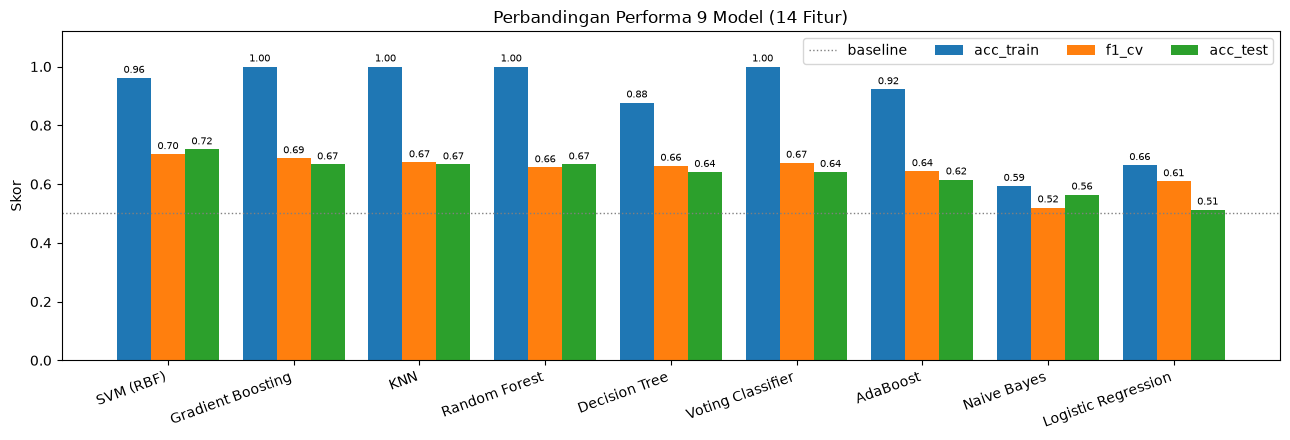

In [17]:
import numpy as np
import matplotlib.pyplot as plt

urut = perbandingan.set_index("model")
metrik = ["acc_train", "f1_cv", "acc_test"]
x = np.arange(len(urut))
lebar = 0.27

fig, ax = plt.subplots(figsize=(13, 4.5))
for k, m in enumerate(metrik):
    batang = ax.bar(x + (k - 1) * lebar, urut[m], lebar, label=m)
    ax.bar_label(batang, fmt="%.2f", fontsize=7, padding=2)
ax.axhline(y.value_counts(normalize=True).max(), color="gray", linestyle=":", lw=1, label="baseline")
ax.set_xticks(x, urut.index, rotation=20, ha="right")
ax.set(ylim=(0, 1.12), ylabel="Skor", title="Perbandingan Performa 9 Model (14 Fitur)")
ax.legend(loc="upper right", ncol=4)
plt.tight_layout()
plt.show()

#### Analisis
- **SVM (RBF)** meraih akurasi uji tertinggi, **71,79%** (28 dari 39 citra benar), sekaligus F1 makro tertinggi (0,72). Berikutnya Gradient Boosting, KNN, dan Random Forest dengan **66,67%** (26 dari 39).
- Data uji berisi 20 citra berantakan dan 19 rapi, sehingga menebak satu kelas saja menghasilkan **51,28%**. Semua model berada di atas angka ini kecuali **Logistic Regression** (51,28%), yang setara dengan menebak.
- SVM juga memiliki `f1_cv` tertinggi (0,70), sehingga hasil validasi pada data latih dan hasil pada data uji sejalan untuk model ini.
- Dengan 39 citra uji, satu citra bernilai sekitar 2,6 poin persen. Selisih antar-model yang hanya 1–2 citra belum bisa dianggap perbedaan nyata, sehingga perlu dicek ulang di Tahap 5.3.

### 5.2 *Confusion Matrix* pada Data Uji
*Confusion matrix* untuk dua kelas berbentuk 2 × 2. Baris adalah kelas sebenarnya dan kolom adalah kelas prediksi:

| | Prediksi rapi | Prediksi berantakan |
| :--- | :---: | :---: |
| **Sebenarnya rapi** | benar | salah |
| **Sebenarnya berantakan** | salah | benar |

Diagonal utama (kiri atas dan kanan bawah) adalah prediksi yang benar, sehingga $\text{akurasi} = \dfrac{\text{jumlah diagonal}}{\text{jumlah seluruh sel}}$.

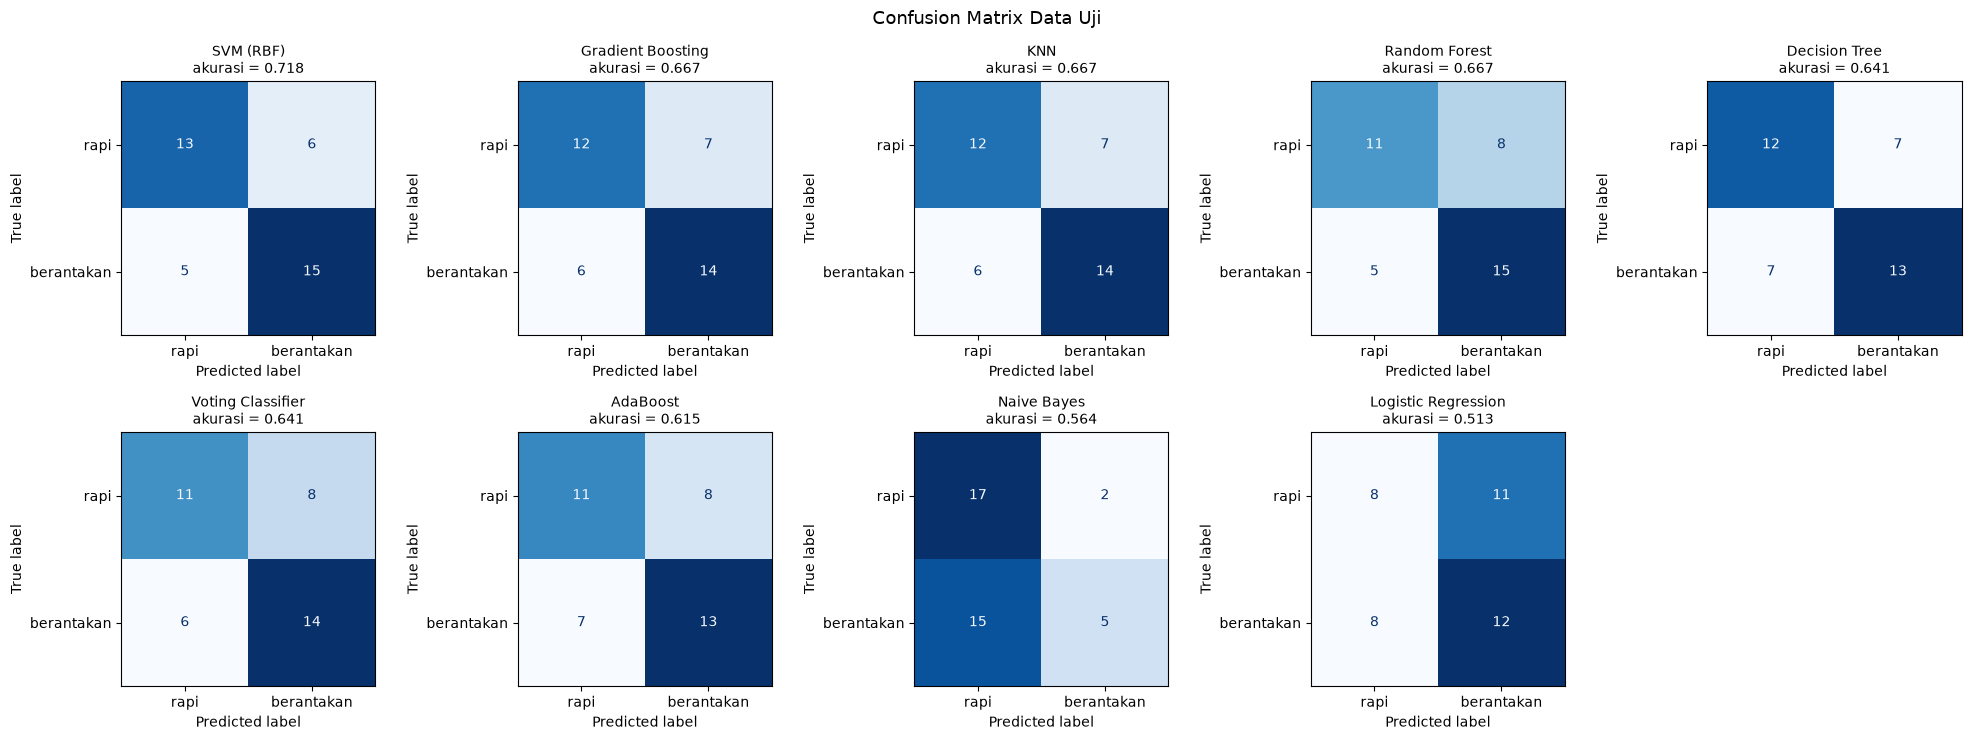

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, nama in zip(axes.ravel(), perbandingan["model"]):
    pred = model_terlatih[nama].predict(X_test)
    cm = confusion_matrix(y_test, pred, labels=KELAS)
    ConfusionMatrixDisplay(cm, display_labels=KELAS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{nama}\nakurasi = {accuracy_score(y_test, pred):.3f}", fontsize=10)
for ax in axes.ravel()[len(perbandingan):]:
    ax.axis("off")
plt.suptitle("Confusion Matrix Data Uji", fontsize=13)
plt.tight_layout()
plt.show()

### 5.3 Validasi Silang Berulang pada Seluruh Data
Data uji hanya berisi 39 citra, sehingga hasilnya bisa kebetulan mudah atau sulit. Untuk penilaian yang lebih stabil, setiap model dengan parameter terbaiknya diuji ulang dengan **5-fold *Stratified K-Fold* pada seluruh 194 citra**, diulang 3 kali dengan pengacakan berbeda (`RepeatedStratifiedKFold`, **15 pembagian**). Setiap citra pernah menjadi data uji.

Sebagai pembanding dipakai **baseline**: akurasi jika model selalu menebak satu kelas saja. Karena jumlah kedua kelas sama (97:97), baseline-nya **50%**. Model yang berguna harus lebih tinggi dari baseline.

In [19]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

BASELINE = (y == "berantakan").mean()

baris = []
for nama, model in model_terlatih.items():
    skor = cross_val_score(clone(model), X, y, scoring="accuracy",
                           cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42))
    baris.append({"model": nama, "akurasi_rata2": skor.mean(), "akurasi_std": skor.std(),
                  "akurasi_min": skor.min(), "akurasi_maks": skor.max(),
                  "selisih_baseline": skor.mean() - BASELINE})

validasi = pd.DataFrame(baris).sort_values("akurasi_rata2", ascending=False).reset_index(drop=True).round(4)
validasi.to_csv(os.path.join(FOLDER_HASIL, "validasi_silang.csv"), index=False)
print(f"Baseline (menebak satu kelas saja): {BASELINE:.4f}")
validasi

Baseline (menebak satu kelas saja): 0.5000


,model,akurasi_rata2,akurasi_std,akurasi_min,akurasi_maks,selisih_baseline
0,KNN,0.6821,0.0745,0.5385,0.7949,0.1821
1,SVM (RBF),0.6650,0.0651,0.5641,0.7692,0.1650
2,Voting Classifier,0.6496,0.0708,0.5128,0.7436,0.1496
3,Random Forest,0.6495,0.0751,0.5128,0.8205,0.1495
4,Gradient Boosting,0.6393,0.0702,0.4872,0.7692,0.1393
5,Logistic Regression,0.6273,0.0852,0.4615,0.7692,0.1273
6,AdaBoost,0.6153,0.0698,0.4872,0.7368,0.1153
7,Decision Tree,0.5862,0.0656,0.4615,0.6923,0.0862
8,Naive Bayes,0.5773,0.0552,0.4359,0.6923,0.0773


#### Analisis
- **KNN** memiliki rata-rata akurasi tertinggi, **68,21%**, disusul SVM (66,50%), Voting Classifier (64,96%), dan Random Forest (64,95%). Semua model berada di atas baseline 50%.
- **Naive Bayes** (57,73%) dan **Decision Tree** (58,62%) paling rendah.
- Urutan model berbeda dari Tahap 5.1: SVM terbaik di data uji, sedangkan KNN terbaik di validasi silang. Selisih KNN dan SVM hanya 1,7 poin, jauh lebih kecil dari standar deviasinya (±7 poin), sehingga kemampuan keduanya praktis setara.
- Akurasi KNN berkisar dari 53,85% sampai 79,49% antar-pembagian, sehingga hasil satu kali pembagian 80:20 tidak cukup dijadikan satu-satunya acuan.

### 5.4 Penentuan dan Evaluasi Diagnostik Model Terbaik
Model terbaik ditentukan dari **rata-rata akurasi validasi silang berulang (Tahap 5.3)**, karena nilainya dihitung dari 15 pembagian sehingga lebih stabil dibanding satu data uji kecil.

Untuk melihat jenis kesalahannya, setiap citra diprediksi dengan `cross_val_predict` (5-fold): **setiap citra diprediksi oleh model yang tidak dilatih dengan citra itu**. Hasilnya adalah *confusion matrix* dari seluruh 194 citra.

=== MODEL TERBAIK: KNN ===
Parameter        : {'n_neighbors': 11, 'weights': 'distance'}
Akurasi (194 citra, cross_val_predict): 72.68% (141 dari 194 benar)

              precision    recall  f1-score   support

        rapi     0.7157    0.7526    0.7337        97
  berantakan     0.7391    0.7010    0.7196        97

    accuracy                         0.7268       194
   macro avg     0.7274    0.7268    0.7266       194
weighted avg     0.7274    0.7268    0.7266       194



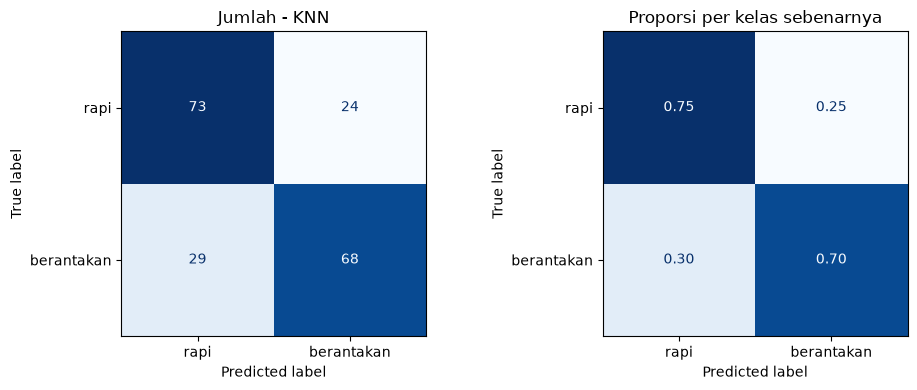

In [20]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

MODEL_TERBAIK = validasi.loc[0, "model"]
model_terbaik = model_terlatih[MODEL_TERBAIK]

pred_semua = cross_val_predict(clone(model_terbaik), X, y,
                               cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))

print(f"=== MODEL TERBAIK: {MODEL_TERBAIK} ===")
print("Parameter        :", df_hasil.set_index("model").loc[MODEL_TERBAIK, "parameter"])
print(f"Akurasi ({len(y)} citra, cross_val_predict): {accuracy_score(y, pred_semua):.2%} "
      f"({(pred_semua == y).sum()} dari {len(y)} benar)\n")
print(classification_report(y, pred_semua, labels=KELAS, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y, pred_semua, labels=KELAS),
                       display_labels=KELAS).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Jumlah - {MODEL_TERBAIK}")
ConfusionMatrixDisplay(confusion_matrix(y, pred_semua, labels=KELAS, normalize="true"),
                       display_labels=KELAS).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Proporsi per kelas sebenarnya")
plt.tight_layout()
plt.show()

#### Analisis
- Model terbaik menurut validasi silang adalah **KNN** (`n_neighbors=11`, `weights="distance"`). Dari 194 citra, **141 diprediksi benar (72,68%)**.
- Kemampuan mengenali kedua kelas cukup seimbang: *recall* **rapi 75,26%** (73 dari 97) dan **berantakan 70,10%** (68 dari 97).
- Kesalahan terjadi ke dua arah: 24 citra rapi diprediksi berantakan dan 29 citra berantakan diprediksi rapi. *Precision* kedua kelas 72–74%, artinya sekitar seperempat prediksi masih salah.
- Karena jumlah data kedua kelas sama, model tidak condong ke salah satu kelas.